# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** Abdul Sami
- **Student ID:**  023-24-0211
- **Section:** G
- **GitHub:** https://github.com/abdulsami911/Machine_learning_Practical
- **Kaggle:** https://www.kaggle.com/abdulsami911
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
import warnings
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.dpi"] = 100
print("Setup done, SEED =", SEED)

Setup done, SEED = 42


### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [2]:
df = pd.read_csv("Mall_Customers.csv")
df = df.rename(columns={"Annual Income (k$)": "Income", "Spending Score (1-100)": "Spending"})

print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nGender counts:")
print(df["Gender"].value_counts())
print()
df[["Age", "Income", "Spending"]].describe().round(2)

Shape: (200, 5)
Missing values: 0
Duplicate rows: 0

Gender counts:
Gender
Female    112
Male       88
Name: count, dtype: int64



,Age,Income,Spending
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


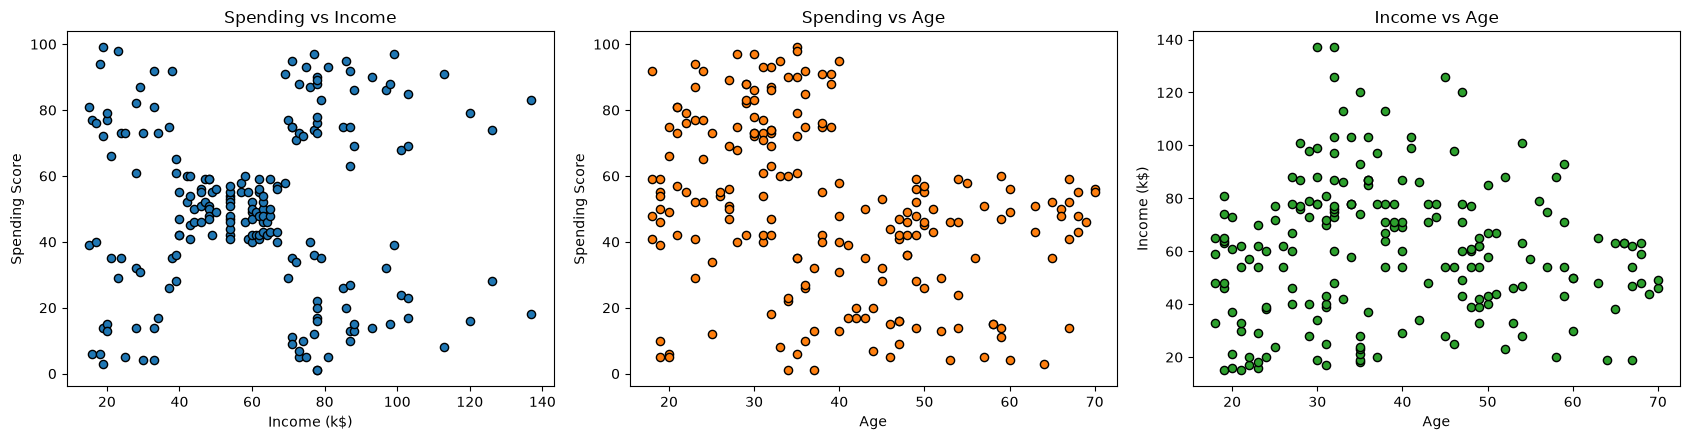

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

ax[0].scatter(df["Income"], df["Spending"], c="tab:blue", edgecolor="k", s=35)
ax[0].set_xlabel("Income (k$)"); ax[0].set_ylabel("Spending Score")
ax[0].set_title("Spending vs Income")

ax[1].scatter(df["Age"], df["Spending"], c="tab:orange", edgecolor="k", s=35)
ax[1].set_xlabel("Age"); ax[1].set_ylabel("Spending Score")
ax[1].set_title("Spending vs Age")

ax[2].scatter(df["Age"], df["Income"], c="tab:green", edgecolor="k", s=35)
ax[2].set_xlabel("Age"); ax[2].set_ylabel("Income (k$)")
ax[2].set_title("Income vs Age")

plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

**(a)** In *Spending vs Income* I can clearly see **5 groups**: a low-income/low-spending corner, a low-income/high-spending corner, one big block in the middle (income about 40-70, spending about 40-60), and two groups at high income (one high spending, one low spending). This is the plot that shows the groups most clearly. In *Spending vs Age* there are no clear groups, only a rough triangle (young customers reach spending 99, older ones rarely go above 60), so maybe 2 loose bands at best. In *Income vs Age* I see one big cloud with no separation at all (0 clear groups).

**(b)** Accuracy compares a prediction with the true answer, and here there is no true answer column, so there is nothing to compare with. A train/test split is also pointless because we have no `y` to learn and no test labels to check. K-Means only finds structure in the features, so we judge it with inertia, silhouette, plots and whether the groups make business sense.

---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [4]:
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
m = np.array([4.0, 11.0])          # starting centroids from the lecture

print("Data:", x.astype(int).tolist())
print("Start centroids:", m)

it = 0
while True:
    it += 1
    dist = np.abs(x[:, None] - m[None, :])       # shape (9, 2)
    lab = dist.argmin(axis=1)                    # assign step
    new_m = np.array([x[lab == k].mean() for k in range(2)])   # update step

    print(f"\n--- Iteration {it} ---")
    print("C1 =", x[lab == 0].astype(int).tolist(), "-> new centroid", round(new_m[0], 2))
    print("C2 =", x[lab == 1].astype(int).tolist(), "-> new centroid", round(new_m[1], 2))

    if np.allclose(new_m, m):                    # stop when no centroid changes
        break
    m = new_m

final_inertia = ((x - m[lab]) ** 2).sum()
print("\nFinal centroids:", m)
print("Final inertia  :", final_inertia)
print("Lecture slides : centroids 7 and 25, inertia 150  ->",
      "MATCH" if np.allclose(m, [7, 25]) and np.isclose(final_inertia, 150) else "DIFFERENT")

Data: [2, 4, 10, 12, 3, 20, 30, 11, 25]
Start centroids: [ 4. 11.]

--- Iteration 1 ---
C1 = [2, 4, 3] -> new centroid 3.0
C2 = [10, 12, 20, 30, 11, 25] -> new centroid 18.0

--- Iteration 2 ---
C1 = [2, 4, 10, 3] -> new centroid 4.75
C2 = [12, 20, 30, 11, 25] -> new centroid 19.6

--- Iteration 3 ---
C1 = [2, 4, 10, 12, 3, 11] -> new centroid 7.0
C2 = [20, 30, 25] -> new centroid 25.0

--- Iteration 4 ---
C1 = [2, 4, 10, 12, 3, 11] -> new centroid 7.0
C2 = [20, 30, 25] -> new centroid 25.0

Final centroids: [ 7. 25.]
Final inertia  : 150.0
Lecture slides : centroids 7 and 25, inertia 150  -> MATCH


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [5]:
P = np.array([[185, 72], [170, 56], [168, 60], [179, 68], [182, 72], [188, 77]], dtype=float)
names = ["P1", "P2", "P3", "P4", "P5", "P6"]
M = P[[0, 1]].copy()                # start with P1 and P2

it = 0
while True:
    it += 1
    D = np.sqrt(((P[:, None, :] - M[None, :, :]) ** 2).sum(axis=2))   # (6, 2) Euclidean
    lab = D.argmin(axis=1)
    new_M = np.array([P[lab == k].mean(axis=0) for k in range(2)])

    print(f"--- Iteration {it} ---")
    print("Distance table (columns = M1, M2):")
    print(pd.DataFrame(D.round(2), index=names, columns=["d(M1)", "d(M2)"]).assign(Cluster=lab + 1))
    print("New centroids: M1 =", new_M[0].round(2), " M2 =", new_M[1].round(2), "\n")

    if np.allclose(new_M, M):
        break
    M = new_M

print("Final centroids: M1 =", M[0].round(2), " M2 =", M[1].round(2))

# hand check of the lecture value d(P3, M2) in the FIRST iteration (M2 = P2 = (170, 56))
d_hand = np.sqrt((168 - 170) ** 2 + (60 - 56) ** 2)
print("\nHand check d(P3, M2) in iteration 1 = sqrt((168-170)^2 + (60-56)^2) = sqrt(4+16) = sqrt(20) =", round(d_hand, 2))

--- Iteration 1 ---
Distance table (columns = M1, M2):
    d(M1)  d(M2)  Cluster
P1   0.00  21.93        1
P2  21.93   0.00        2
P3  20.81   4.47        2
P4   7.21  15.00        1
P5   3.00  20.00        1
P6   5.83  27.66        1
New centroids: M1 = [183.5   72.25]  M2 = [169.  58.] 

--- Iteration 2 ---
Distance table (columns = M1, M2):
    d(M1)  d(M2)  Cluster
P1   1.52  21.26        1
P2  21.13   2.24        2
P3  19.76   2.24        2
P4   6.19  14.14        1
P5   1.52  19.10        1
P6   6.54  26.87        1
New centroids: M1 = [183.5   72.25]  M2 = [169.  58.] 

Final centroids: M1 = [183.5   72.25]  M2 = [169.  58.]

Hand check d(P3, M2) in iteration 1 = sqrt((168-170)^2 + (60-56)^2) = sqrt(4+16) = sqrt(20) = 4.47


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [6]:
def my_kmeans(X, init_centroids, max_iter=100):
    """K-Means from scratch (Lloyd's algorithm). No sklearn KMeans used.
    Returns: labels, centroids, inertia, number of iterations."""
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X[:, None]
    C = np.asarray(init_centroids, dtype=float).reshape(len(init_centroids), -1).copy()
    K = len(C)

    n_iter = 0
    for n_iter in range(1, max_iter + 1):
        # assign: distance of every point to every centroid (broadcasting)
        d = np.sqrt(((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))
        labels = d.argmin(axis=1)

        # update: mean of the points of each cluster (empty cluster keeps old centroid)
        new_C = C.copy()
        for k in range(K):
            if np.any(labels == k):
                new_C[k] = X[labels == k].mean(axis=0)

        converged = np.allclose(new_C, C)
        C = new_C
        if converged:
            break

    d = np.sqrt(((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))
    labels = d.argmin(axis=1)
    inertia = (d[np.arange(len(X)), labels] ** 2).sum()
    return labels, C, inertia, n_iter

In [7]:
# Test on lecture Example 1
lab1, C1, inert1, n1 = my_kmeans(x, [4, 11])
print("Labels    :", lab1)
print("Centroids :", C1.ravel())
print("Inertia   :", inert1)
print("Iterations:", n1)
print("Matches lecture (7, 25, 150)?", np.allclose(C1.ravel(), [7, 25]) and np.isclose(inert1, 150))

Labels    : [0 0 0 0 0 1 1 0 1]
Centroids : [ 7. 25.]
Inertia   : 150.0
Iterations: 4
Matches lecture (7, 25, 150)? True


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [8]:
X2 = df[["Income", "Spending"]].values.astype(float)    # 200 x 2
init5 = X2[:5].copy()                                  # first 5 rows as starting centroids

# my function
lab_my, C_my, in_my, it_my = my_kmeans(X2, init5)

# scikit-learn with exactly the same start
km_sk = KMeans(n_clusters=5, init=init5, n_init=1, tol=0, algorithm="lloyd").fit(X2)

print(f"{'':12s}{'my_kmeans':>14s}{'sklearn':>14s}")
print(f"{'Iterations':12s}{it_my:>14d}{km_sk.n_iter_:>14d}")
print(f"{'Inertia':12s}{in_my:>14.4f}{km_sk.inertia_:>14.4f}")
print()
print("Labels identical        :", np.array_equal(lab_my, km_sk.labels_))
print("Centroids identical     :", np.allclose(C_my, km_sk.cluster_centers_))
print("Max centroid difference :", np.abs(C_my - km_sk.cluster_centers_).max())
print()
print("Final centroids (Income, Spending):")
print(pd.DataFrame(np.hstack([C_my, km_sk.cluster_centers_]).round(3),
                   columns=["my_Inc", "my_Spend", "sk_Inc", "sk_Spend"]))

                 my_kmeans       sklearn
Iterations               4             4
Inertia         44448.4554    44448.4554

Labels identical        : True
Centroids identical     : True
Max centroid difference : 2.842170943040401e-14

Final centroids (Income, Spending):
   my_Inc  my_Spend  sk_Inc  sk_Spend
0  26.304    20.913  26.304    20.913
1  25.727    79.364  25.727    79.364
2  88.200    17.114  88.200    17.114
3  86.538    82.128  86.538    82.128
4  55.296    49.519  55.296    49.519


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

**(a)** In iteration 1 the centroids were 4 and 11. For the point 10: |10-4| = 6 and |10-11| = 1, so it went to C2. After the update the centroids became 3 and 18 (C2 was pulled far to the right by 20, 30 and 25). Now |10-3| = 7 and |10-18| = 8, so 10 is closer to C1 and it moved there. The centroid of C2 moved away from it, that is the reason.

**(b)** The loop stops when the assign step gives the same clusters as before, so the centroids do not move any more (Example 1 stopped at iteration 4, the Mall data also at 4). It must stop because both steps can only lower (or keep) the inertia: assigning to the nearest centroid never raises it and replacing a centroid by the mean never raises it. There is only a finite number of ways to split the points into K groups, so the inertia cannot keep falling and the algorithm cannot cycle. But it only reaches a *local* minimum, so another starting point can end in a different (worse) answer, as Part 3 shows.

**(c)** Yes, it matched exactly. Both took 4 iterations, inertia was 44448.4554 in both, the labels were identical (`np.array_equal` = True) and the centroids were the same (largest difference 2.8e-14, which is only floating point rounding). This is expected because both run the same Lloyd algorithm from the same start with `tol=0`.

**(d)** A centroid is the average customer of a group. For example the group with centroid (Income 86.5, Spending 82.1) is the typical rich big spender. It does not have to be a real customer. K-Means needs numeric features because it calculates means and Euclidean distances (subtract, square, add). You cannot take the mean of "Male" and "Female" or subtract two text values, so categories must be converted to numbers first.

---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


 K    Inertia  Silhouette  Inertia drop
 2 181363.596       0.297           NaN
 3 106348.373       0.468     75015.223
 4  73679.789       0.493     32668.584
 5  44448.455       0.554     29231.334
 6  37233.815       0.540      7214.641
 7  30241.344       0.529      6992.471
 8  25036.418       0.455      5204.926
 9  21916.795       0.456      3119.623
10  20072.071       0.441      1844.724

K with the highest silhouette: 5 -> 0.5539


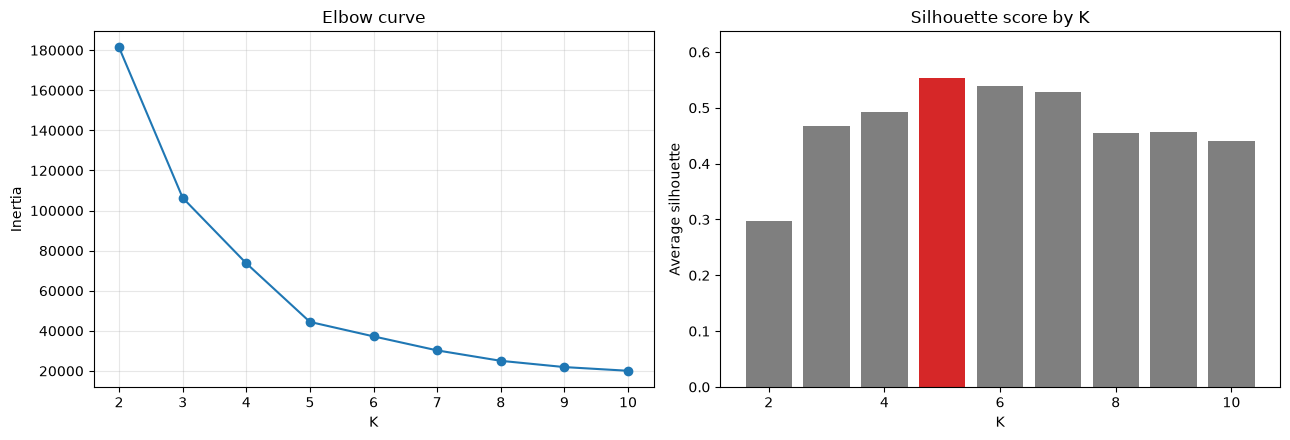

In [9]:
Ks = range(2, 11)
rows = []
for k in Ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X2)
    rows.append([k, km.inertia_, silhouette_score(X2, km.labels_)])

res = pd.DataFrame(rows, columns=["K", "Inertia", "Silhouette"])
res["Inertia drop"] = -res["Inertia"].diff()
print(res.round(3).to_string(index=False))

best_k = int(res.loc[res["Silhouette"].idxmax(), "K"])
print("\nK with the highest silhouette:", best_k, "->", round(res["Silhouette"].max(), 4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(res["K"], res["Inertia"], "o-", color="tab:blue")
ax[0].set_xlabel("K"); ax[0].set_ylabel("Inertia"); ax[0].set_title("Elbow curve")
ax[0].grid(alpha=0.3)

colors = ["tab:red" if k == best_k else "tab:gray" for k in res["K"]]
ax[1].bar(res["K"], res["Silhouette"], color=colors)
ax[1].set_xlabel("K"); ax[1].set_ylabel("Average silhouette"); ax[1].set_title("Silhouette score by K")
ax[1].set_ylim(0, res["Silhouette"].max() * 1.15)
plt.tight_layout()
plt.show()

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [10]:
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
lab5 = km5.labels_

def silhouette_by_hand(X, labels, i):
    """Return a, b, s for point i using only NumPy distances."""
    d = np.sqrt(((X - X[i]) ** 2).sum(axis=1))        # distance from point i to all points
    own = labels[i]
    same = (labels == own)
    same[i] = False                                    # do not count the point itself
    a = d[same].mean() if same.any() else 0.0
    b = min(d[labels == c].mean() for c in np.unique(labels) if c != own)
    s = (b - a) / max(a, b)
    return a, b, s

a0, b0, s0 = silhouette_by_hand(X2, lab5, 0)
s_all = silhouette_samples(X2, lab5)
print(f"Customer 1 (row 0): Income={X2[0,0]:.0f}, Spending={X2[0,1]:.0f}, cluster={lab5[0]}")
print(f"  a = {a0:.4f}")
print(f"  b = {b0:.4f}")
print(f"  s (by hand)        = {s0:.4f}")
print(f"  s (silhouette_samples) = {s_all[0]:.4f}")
print("  Same value?", np.isclose(s0, s_all[0]))

Customer 1 (row 0): Income=15, Spending=39, cluster=4
  a = 24.6404
  b = 42.2653
  s (by hand)        = 0.4170
  s (silhouette_samples) = 0.4170
  Same value? True


         Count  Mean_s  Min_s
Cluster                      
0           81   0.597  0.115
1           39   0.509  0.225
2           22   0.599  0.051
3           35   0.504 -0.023
4           23   0.512 -0.009

Customers with negative silhouette: 2
Overall average silhouette        : 0.5539


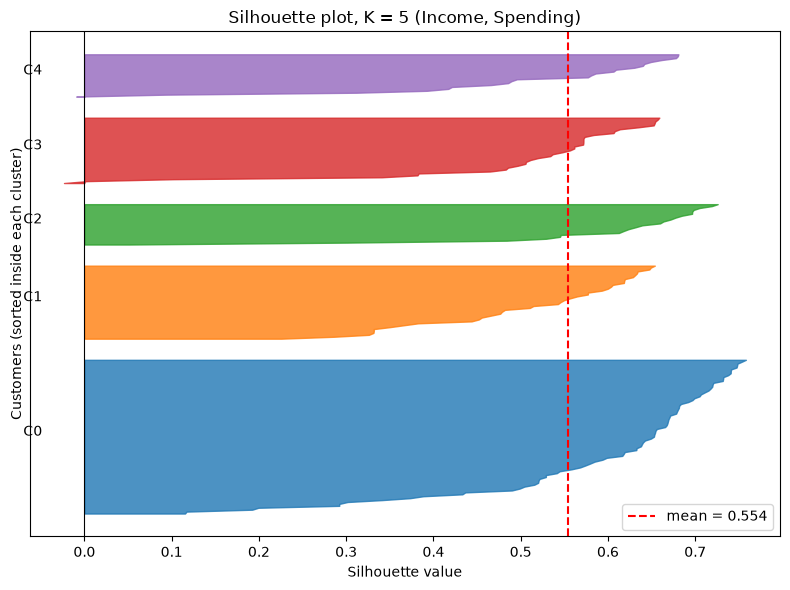

In [11]:
# per-cluster summary
sil_df = pd.DataFrame({"Cluster": lab5, "s": s_all})
summary = sil_df.groupby("Cluster")["s"].agg(Count="count", Mean_s="mean", Min_s="min").round(3)
print(summary)
print("\nCustomers with negative silhouette:", int((s_all < 0).sum()))
print("Overall average silhouette        :", round(s_all.mean(), 4))

# silhouette plot
fig, ax = plt.subplots(figsize=(8, 6))
y_low = 10
cmap = plt.cm.tab10
for c in range(5):
    sc = np.sort(s_all[lab5 == c])
    y_up = y_low + len(sc)
    ax.fill_betweenx(np.arange(y_low, y_up), 0, sc, color=cmap(c), alpha=0.8)
    ax.text(-0.07, y_low + 0.5 * len(sc), f"C{c}", fontsize=10)
    y_low = y_up + 10
ax.axvline(s_all.mean(), color="red", linestyle="--", label=f"mean = {s_all.mean():.3f}")
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Silhouette value"); ax.set_ylabel("Customers (sorted inside each cluster)")
ax.set_yticks([]); ax.set_title("Silhouette plot, K = 5 (Income, Spending)")
ax.legend()
plt.tight_layout()
plt.show()

### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [12]:
pts = np.array([1, 3, 5, 7, 11, 13, 15], dtype=float)
labp, Cp, inp, itp = my_kmeans(pts, [1, 11])

print("Final clusters:")
for k in range(2):
    print(f"  C{k+1} =", pts[labp == k].astype(int).tolist(), " centroid =", Cp[k, 0])
print("Inertia   :", inp)
print("Iterations:", itp)

# a, b, s for points 1, 7 and 11
Xp = pts[:, None]
sp = silhouette_samples(Xp, labp)
print("\nPoint |    a    |    b    |  s (hand) | s (sklearn)")
for v in [1, 7, 11]:
    i = int(np.where(pts == v)[0][0])
    a, b, s = silhouette_by_hand(Xp, labp, i)
    print(f"{v:5d} | {a:7.3f} | {b:7.3f} | {s:9.4f} | {sp[i]:9.4f}")
print("\nAverage silhouette:", round(sp.mean(), 4))

Final clusters:
  C1 = [1, 3, 5, 7]  centroid = 4.0
  C2 = [11, 13, 15]  centroid = 13.0
Inertia   : 28.0
Iterations: 3

Point |    a    |    b    |  s (hand) | s (sklearn)
    1 |   4.000 |  12.000 |    0.6667 |    0.6667
    7 |   4.000 |   6.000 |    0.3333 |    0.3333
   11 |   3.000 |   7.000 |    0.5714 |    0.5714

Average silhouette: 0.6395


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



**Your answers:**

**(a)** The elbow suggests **K = 5**. Inertia fell by 29,231 from K=4 (73,680) to K=5 (44,448) but only by 7,215 from K=5 to K=6 (37,234), and after that the drops are 6,992, 5,205, 3,120 and 1,845, so the curve bends at 5. The silhouette is also highest at **K = 5 (0.554)**, then K=6 (0.540) and K=7 (0.529). So they agree and I choose K = 5.

**(b)** Customer 1 (Income 15, Spending 39) has a = 24.64, b = 42.27 and s = **0.417** (my function and `silhouette_samples` gave the same value). It is in the right cluster (positive, clearly above 0) but not deeply inside it, because its spending 39 is higher than the cluster average of 20.9, so it sits near the edge toward the middle group. The cluster with the weakest average silhouette is **cluster 3** (high income / low spending, mean 0.504, 35 customers); cluster 4 is close with 0.512. **2 customers** have a negative silhouette (minimum -0.023 in cluster 3 and -0.009 in cluster 4), and both are almost 0, so they just sit on a border.

**(c)** Point 7 is less well placed. Point 1 has a = 4.0, b = 12.0, so s = 0.667. Point 7 has the same a = 4.0 but b = only 6.0 (the other cluster is close), so s = 0.333. Point 7 is at the boundary between the two clusters while point 1 is far from the other cluster.

**(d)** Inertia always goes down when K goes up. If K = number of points, every point is its own cluster and inertia is 0, but that tells us nothing. In my table it falls from 44,448 (K=5) to 20,072 (K=10) even though the groups got worse (silhouette 0.554 to 0.441). So we need the elbow (where the gain becomes small), the silhouette and business meaning, not the lowest inertia.

---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


Best inertia over all 90 runs: 44448.5 

             Setting  Distinct inertias  Lowest  Highest  % runs at best
    random, n_init=1                 14 44448.5  91762.0            33.3
 k-means++, n_init=1                  6 44448.5  66733.4            60.0
k-means++, n_init=10                  1 44448.5  44448.5           100.0


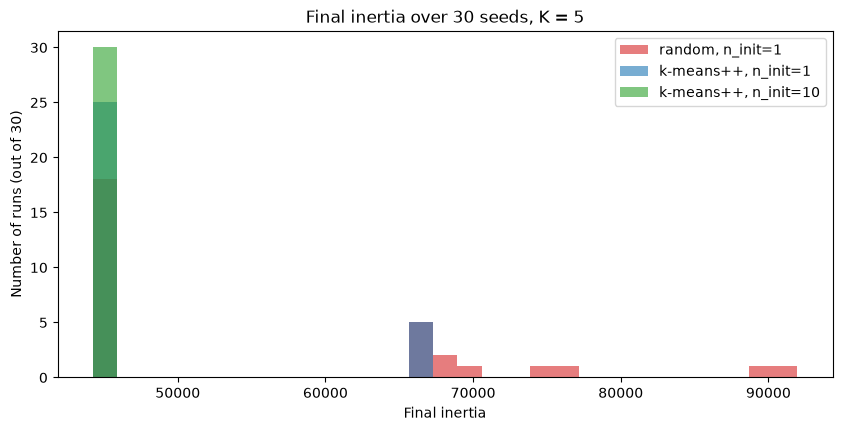

In [13]:
K = 5
settings = {
    "random, n_init=1":     dict(init="random",    n_init=1),
    "k-means++, n_init=1":  dict(init="k-means++", n_init=1),
    "k-means++, n_init=10": dict(init="k-means++", n_init=10),
}

runs = {}      # setting -> list of fitted models
for name, kw in settings.items():
    runs[name] = [KMeans(n_clusters=K, random_state=s, **kw).fit(X2) for s in range(30)]

best_overall = round(min(m.inertia_ for ms in runs.values() for m in ms), 1)
print("Best inertia over all 90 runs:", best_overall, "\n")

rows = []
for name, ms in runs.items():
    vals = np.round([m.inertia_ for m in ms], 1)
    rows.append([name, len(np.unique(vals)), vals.min(), vals.max(),
                 100 * np.mean(vals == best_overall)])
tab = pd.DataFrame(rows, columns=["Setting", "Distinct inertias", "Lowest", "Highest", "% runs at best"])
print(tab.round(1).to_string(index=False))

plt.figure(figsize=(10, 4.5))
allv = np.concatenate([[m.inertia_ for m in ms] for ms in runs.values()])
bins = np.linspace(allv.min() - 200, allv.max() + 200, 30)
for (name, ms), c in zip(runs.items(), ["tab:red", "tab:blue", "tab:green"]):
    plt.hist([m.inertia_ for m in ms], bins=bins, alpha=0.6, label=name, color=c)
plt.xlabel("Final inertia"); plt.ylabel("Number of runs (out of 30)")
plt.title("Final inertia over 30 seeds, K = 5")
plt.legend(); plt.show()

### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


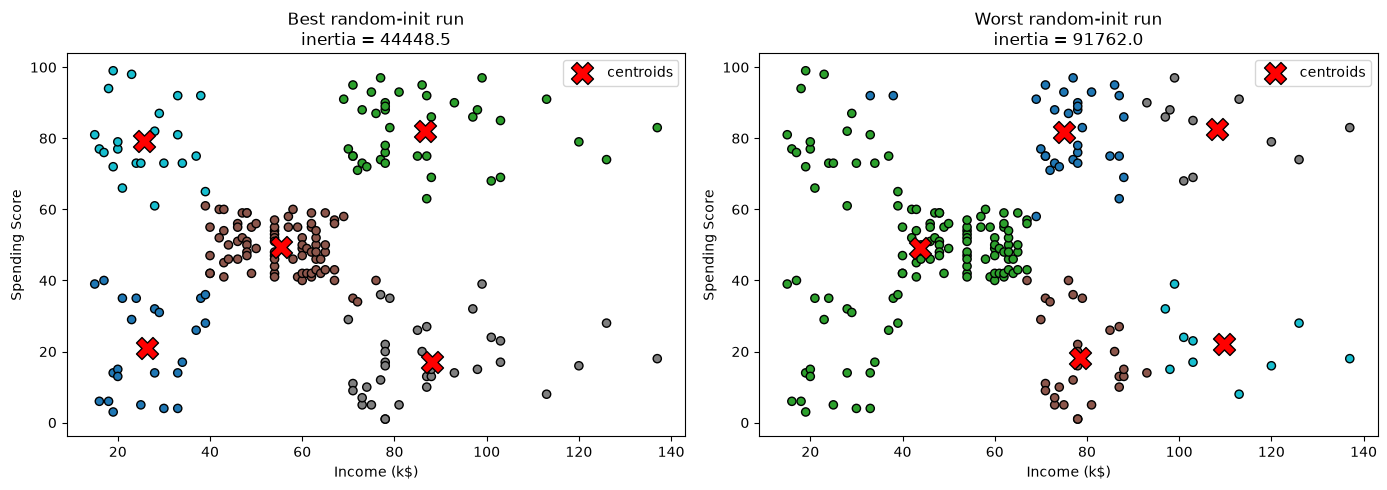

Best  inertia: 44448.46 (seed 0 )
Worst inertia: 91761.98 (seed 13 )
ARI between best and worst: 0.4553


In [14]:
rand_runs = runs["random, n_init=1"]
inertias = np.array([m.inertia_ for m in rand_runs])
best_m  = rand_runs[int(inertias.argmin())]
worst_m = rand_runs[int(inertias.argmax())]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a_, m_, t in zip(ax, [best_m, worst_m], ["Best random-init run", "Worst random-init run"]):
    a_.scatter(X2[:, 0], X2[:, 1], c=m_.labels_, cmap="tab10", edgecolor="k", s=35)
    a_.scatter(m_.cluster_centers_[:, 0], m_.cluster_centers_[:, 1], c="red", marker="X",
               s=250, edgecolor="k", label="centroids")
    a_.set_title(f"{t}\ninertia = {m_.inertia_:.1f}")
    a_.set_xlabel("Income (k$)"); a_.set_ylabel("Spending Score"); a_.legend()
plt.tight_layout(); plt.show()

print("Best  inertia:", round(best_m.inertia_, 2),  "(seed", best_m.random_state, ")")
print("Worst inertia:", round(worst_m.inertia_, 2), "(seed", worst_m.random_state, ")")
print("ARI between best and worst:", round(adjusted_rand_score(best_m.labels_, worst_m.labels_), 4))

**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

**(a)** With `init='random'` and one start, the 30 runs gave **14 different** final inertia values (from 44,448.5 up to 91,762.0), and only **33.3%** (10 of 30) reached the best value. With k-means++ and n_init=1 there were **6** distinct values and **60%** of runs reached the best. With k-means++ and n_init=10 there was only **1** value (44,448.5) and **100%** of the runs reached the best.

**(b)** K-Means is a greedy method, it only improves the answer step by step from where it started and stops at the first point it cannot improve (local minimum). The data has several of these, and the starting centroids decide which one we fall into. Same data and same K but different random starts give different final clusters. The worst run had inertia 91,762, which is about double the best (44,448).

**(c)** k-means++ chooses starting centroids that are far from each other, so a bad start (two centroids in the same group) is less likely; this lifted the success rate from 33.3% to 60%. `n_init=10` runs 10 different starts and keeps the one with the lowest inertia, so the chance that all 10 are bad is very small. In my table n_init=10 gave a single inertia value (44,448.5) in 100% of the 30 seeds.

**(d)** The cluster numbers are arbitrary, cluster 2 in one run can be cluster 4 in another run even if the groups are exactly the same, so comparing label numbers directly would be wrong. ARI compares pairs of points (are they together in both clusterings or not) and ignores the numbers. The best run and the worst run had ARI = 0.455, which shows they are really different groupings.

---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


ARI raw k$     vs raw dollars    : 0.4897
ARI scaled k$  vs scaled dollars : 1.0
ARI raw dollars vs scaled dollars: 0.3605
ARI raw k$     vs scaled k$      : 0.7701

Std of the raw features -> Age: 13.9 | Income (k$): 26.2 | Income ($): 26199


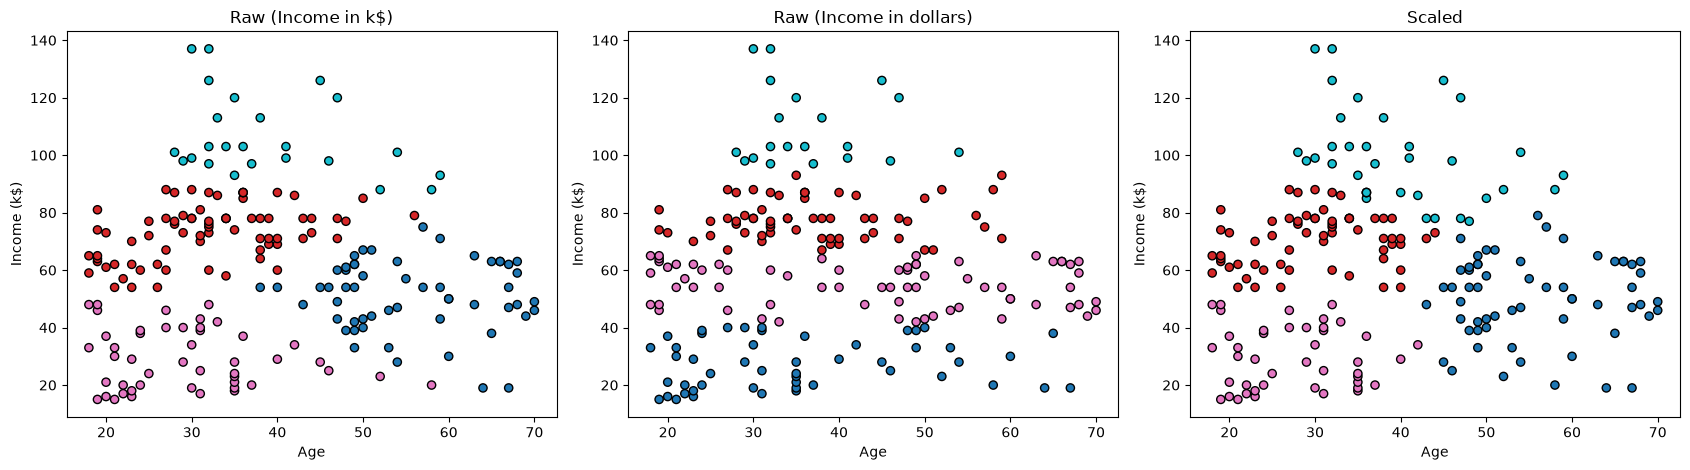

In [15]:
Xa = df[["Age", "Income"]].values.astype(float)
Xa_d = Xa.copy(); Xa_d[:, 1] *= 1000                 # Income in dollars

def fit4(X):
    return KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X)

km_raw_k = fit4(Xa)
km_raw_d = fit4(Xa_d)
km_sc_k  = fit4(StandardScaler().fit_transform(Xa))
km_sc_d  = fit4(StandardScaler().fit_transform(Xa_d))

print("ARI raw k$     vs raw dollars    :", round(adjusted_rand_score(km_raw_k.labels_, km_raw_d.labels_), 4))
print("ARI scaled k$  vs scaled dollars :", round(adjusted_rand_score(km_sc_k.labels_, km_sc_d.labels_), 4))
print("ARI raw dollars vs scaled dollars:", round(adjusted_rand_score(km_raw_d.labels_, km_sc_d.labels_), 4))
print("ARI raw k$     vs scaled k$      :", round(adjusted_rand_score(km_raw_k.labels_, km_sc_k.labels_), 4))

print("\nStd of the raw features -> Age: %.1f | Income (k$): %.1f | Income ($): %.0f"
      % (Xa[:, 0].std(), Xa[:, 1].std(), Xa_d[:, 1].std()))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for a_, m_, t in zip(ax, [km_raw_k, km_raw_d, km_sc_k],
                     ["Raw (Income in k$)", "Raw (Income in dollars)", "Scaled"]):
    a_.scatter(Xa[:, 0], Xa[:, 1], c=m_.labels_, cmap="tab10", edgecolor="k", s=35)
    a_.set_xlabel("Age"); a_.set_ylabel("Income (k$)"); a_.set_title(t)
plt.tight_layout(); plt.show()

### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [16]:
wine = load_wine()
Xw, yw = wine.data, wine.target
sd = pd.Series(Xw.std(axis=0), index=wine.feature_names).sort_values(ascending=False)

print("Three largest standard deviations:")
print(sd.head(3).round(3))
print("\nSmallest standard deviation:")
print(sd.tail(1).round(4))
print("\nRatio largest / smallest: %.0f times" % (sd.iloc[0] / sd.iloc[-1]))
print("Wine shape:", Xw.shape, "| true cultivar sizes:", np.bincount(yw))

Three largest standard deviations:
proline              314.022
magnesium             14.242
alcalinity_of_ash      3.330
dtype: float64

Smallest standard deviation:
nonflavanoid_phenols    0.1241
dtype: float64

Ratio largest / smallest: 2530 times
Wine shape: (178, 13) | true cultivar sizes: [59 71 48]


In [17]:
Xw_s = StandardScaler().fit_transform(Xw)

km_w_raw = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xw)
km_w_sc  = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xw_s)

out = []
for name, X_, m_ in [("Raw", Xw, km_w_raw), ("Scaled", Xw_s, km_w_sc)]:
    out.append([name,
                round(adjusted_rand_score(yw, m_.labels_), 4),
                round(silhouette_score(X_, m_.labels_), 4),
                np.bincount(m_.labels_).tolist()])
print(pd.DataFrame(out, columns=["Data", "ARI vs true cultivar", "Silhouette", "Cluster sizes"]).to_string(index=False))

print("\nWhich feature carries the raw distance? Variance share of each feature in the raw data:")
share = pd.Series(Xw.var(axis=0) / Xw.var(axis=0).sum(), index=wine.feature_names).sort_values(ascending=False)
print((share.head(3) * 100).round(2).astype(str) + " %")

  Data  ARI vs true cultivar  Silhouette Cluster sizes
   Raw                0.3711      0.5711  [62, 47, 69]
Scaled                0.8975      0.2849  [65, 51, 62]

Which feature carries the raw distance? Variance share of each feature in the raw data:
proline              99.77 %
magnesium             0.21 %
alcalinity_of_ash     0.01 %
dtype: str


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


Variance explained by PC1 + PC2: 55.4 %


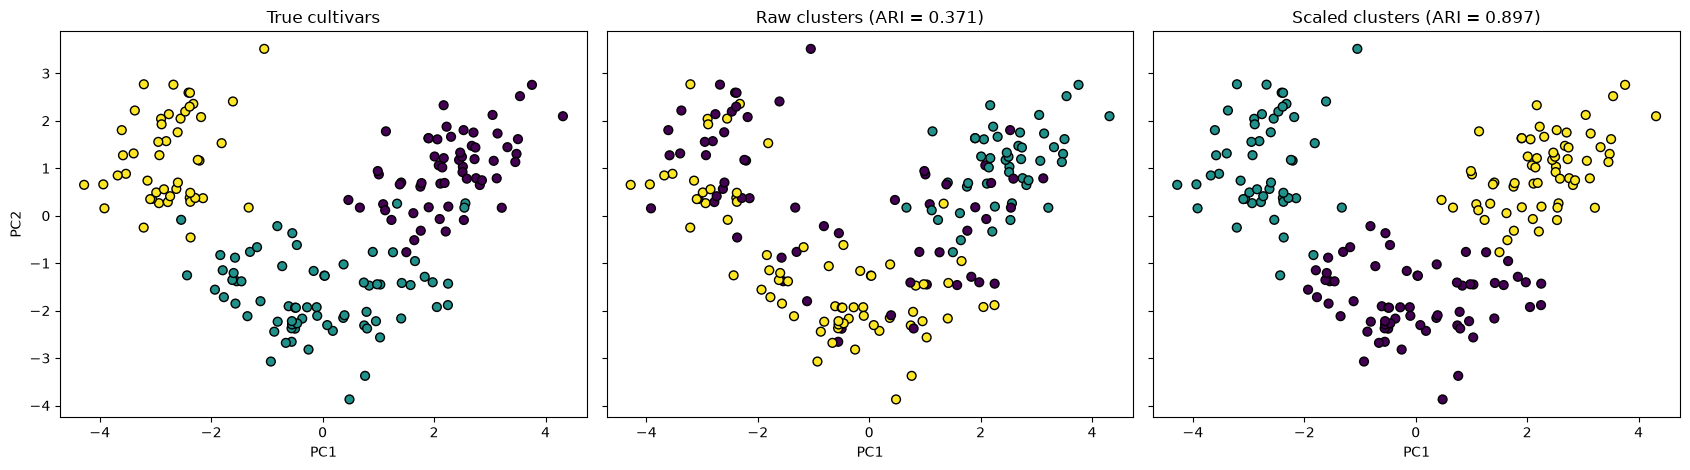

In [18]:
pca = PCA(n_components=2, random_state=SEED).fit(Xw_s)       # one PCA of the SCALED data
Z = pca.transform(Xw_s)
print("Variance explained by PC1 + PC2:", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), sharex=True, sharey=True)
panels = [(yw, "True cultivars"),
          (km_w_raw.labels_, f"Raw clusters (ARI = {adjusted_rand_score(yw, km_w_raw.labels_):.3f})"),
          (km_w_sc.labels_,  f"Scaled clusters (ARI = {adjusted_rand_score(yw, km_w_sc.labels_):.3f})")]
for a_, (lab, t) in zip(ax, panels):
    a_.scatter(Z[:, 0], Z[:, 1], c=lab, cmap="viridis", edgecolor="k", s=40)
    a_.set_title(t); a_.set_xlabel("PC1")
ax[0].set_ylabel("PC2")
plt.tight_layout(); plt.show()

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

**(a)** Distance is sqrt((ΔAge)² + (ΔIncome)²). In k$ the standard deviations are about 13.9 for Age and 26.2 for Income, so Income already counts more but Age still matters. When Income is in dollars its standard deviation becomes about 26,199, so a normal Income difference of 10,000 gives 10,000² = 100,000,000 while an Age difference of 10 gives only 100. **Income now controls the distance completely** and Age is ignored. The clusters changed: ARI between raw k$ and raw dollars was only **0.49**. After scaling, k$ and dollars gave **ARI = 1.0** (identical clusters), because scaling removes the unit. Raw dollars vs scaled dollars was only 0.36.

**(b)** **Proline** dominated. Its standard deviation is 314.0, compared with 14.2 for magnesium, 3.33 for alcalinity of ash and only 0.124 for nonflavanoid phenols (about 2,530 times smaller). Proline carries 99.77% of the raw variance, so the raw clustering is almost a one-feature clustering. ARI against the true cultivar was **0.371 raw** and **0.898 scaled**.

**(c)** The silhouette only measures how compact and separated the groups are *in the space where it is computed*. In the raw data that space is basically just proline, so the clusters look like clean separate intervals and the silhouette is high (0.571), but those groups do not match the real cultivars (ARI 0.371). In the scaled data all 13 features count and the real groups overlap more, so the silhouette is lower (0.285) even though the clustering is much better (ARI 0.898). Raw and scaled silhouettes use different distances, so comparing them is not fair, and silhouette cannot tell if the right features were used.

**(d)** My rule: if the features have different units or very different standard deviations, I scale with StandardScaler (and I check that the profiles of the clusters make sense). I only leave data unscaled if all columns have the same unit and the size differences are meaningful on purpose.

---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [19]:
extra = np.array([[400.0, 99.0]])
X_out = np.vstack([X2, extra])                 # 201 rows, the last one is the extreme customer

km_a = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)        # without
km_b = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X_out)     # with

def show(km, title):
    order = np.argsort(km.cluster_centers_[:, 0])          # sort by income
    sizes = np.bincount(km.labels_, minlength=5)
    t = pd.DataFrame(km.cluster_centers_[order].round(1), columns=["Income", "Spending"])
    t["Size"] = sizes[order]
    print(title); print(t.to_string(index=False)); print()

show(km_a, "WITHOUT the extra customer (200 rows)")
show(km_b, "WITH the extra customer (201 rows)")
print("ARI on the original 200 customers:", round(adjusted_rand_score(km_a.labels_, km_b.labels_[:200]), 4))
print("Inertia without / with:", round(km_a.inertia_, 1), "/", round(km_b.inertia_, 1))
print("Cluster that holds the extra customer has size:", np.bincount(km_b.labels_)[km_b.labels_[-1]])

WITHOUT the extra customer (200 rows)
 Income  Spending  Size
   25.7      79.4    22
   26.3      20.9    23
   55.3      49.5    81
   86.5      82.1    39
   88.2      17.1    35

WITH the extra customer (201 rows)
 Income  Spending  Size
   26.3      20.9    23
   48.3      56.5   100
   86.5      82.1    39
   87.0      18.6    38
  400.0      99.0     1

ARI on the original 200 customers: 0.7532
Inertia without / with: 44448.5 / 73679.8
Cluster that holds the extra customer has size: 1


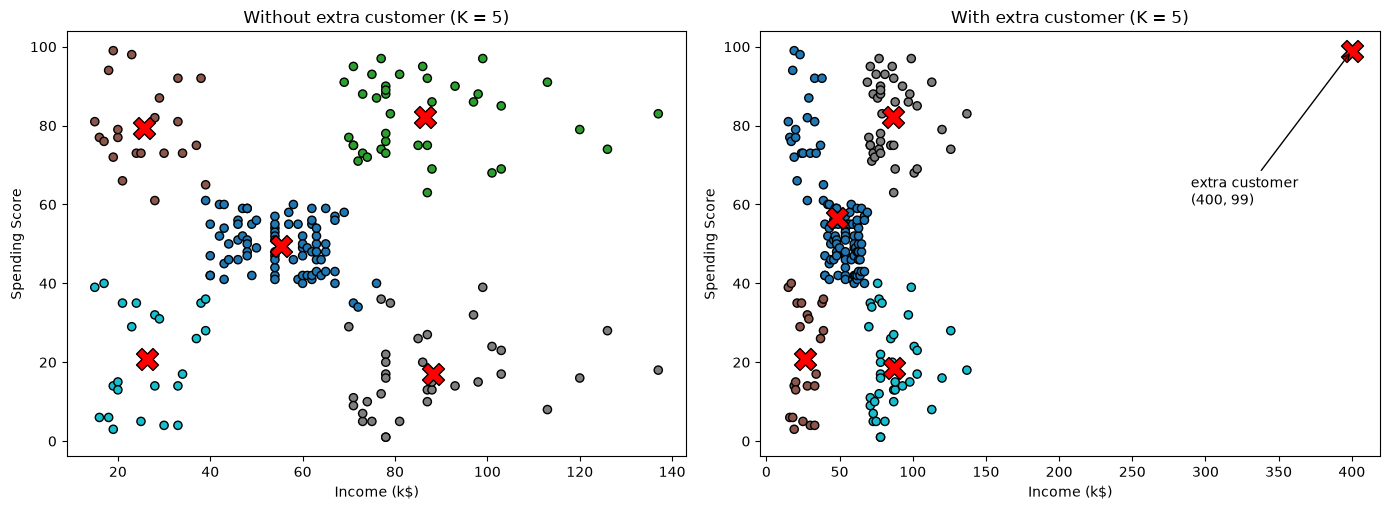

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
ax[0].scatter(X2[:, 0], X2[:, 1], c=km_a.labels_, cmap="tab10", edgecolor="k", s=35)
ax[0].scatter(*km_a.cluster_centers_.T, c="red", marker="X", s=250, edgecolor="k")
ax[0].set_title("Without extra customer (K = 5)")

ax[1].scatter(X_out[:, 0], X_out[:, 1], c=km_b.labels_, cmap="tab10", edgecolor="k", s=35)
ax[1].scatter(*km_b.cluster_centers_.T, c="red", marker="X", s=250, edgecolor="k")
ax[1].annotate("extra customer\n(400, 99)", (400, 99), xytext=(290, 60),
               arrowprops=dict(arrowstyle="->"))
ax[1].set_title("With extra customer (K = 5)")
for a_ in ax:
    a_.set_xlabel("Income (k$)"); a_.set_ylabel("Spending Score")
plt.tight_layout(); plt.show()

### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [21]:
# 1. distance to the nearest centroid (model fitted on the original 200)
d_real  = km_a.transform(X2).min(axis=1)
d_extra = km_a.transform(extra).min(axis=1)[0]

# 2. mean + 3 std rule (mean and std from the 200 real customers)
thr = d_real.mean() + 3 * d_real.std()
flag = d_real > thr
print(f"mean distance = {d_real.mean():.2f}, std = {d_real.std():.2f}, threshold = {thr:.2f}")
print("Real customers flagged :", int(flag.sum()))
print(f"Extra customer distance: {d_extra:.2f}  -> flagged: {d_extra > thr}")

# 3. five real customers farthest from their centroid
chk = df[["CustomerID", "Age", "Income", "Spending"]].copy()
chk["Cluster"] = km_a.labels_
chk["Distance"] = d_real.round(2)
print("\nTop 5 farthest real customers:")
print(chk.sort_values("Distance", ascending=False).head(5).to_string(index=False))

# 4. remove flagged points, refit, compare with the original model using predict
km_c = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2[~flag])
print("\nRefit without flagged points: n =", int((~flag).sum()))
print("Cluster sizes (on kept points):", np.bincount(km_c.labels_).tolist())
ari_rep = adjusted_rand_score(km_a.predict(X2), km_c.predict(X2))
print("ARI vs original model on all 200 customers:", round(ari_rep, 4))
print("\nCentroids of repaired model (sorted by income):")
print(pd.DataFrame(km_c.cluster_centers_[np.argsort(km_c.cluster_centers_[:, 0])].round(1),
                   columns=["Income", "Spending"]).to_string(index=False))

mean distance = 13.02, std = 7.26, threshold = 34.80
Real customers flagged : 4
Extra customer distance: 313.92  -> flagged: True

Top 5 farthest real customers:
 CustomerID  Age  Income  Spending  Cluster  Distance
        200   30     137        83        1     50.47
        199   32     137        18        3     48.81
        198   32     126        74        1     40.29
        197   45     126        28        3     39.34
        196   35     120        79        1     33.61

Refit without flagged points: n = 196
Cluster sizes (on kept points): [80, 34, 23, 37, 22]
ARI vs original model on all 200 customers: 0.9847

Centroids of repaired model (sorted by income):
 Income  Spending
   25.7      79.4
   26.3      20.9
   55.1      49.7
   84.1      82.3
   85.2      17.3


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

**(a)** The extra customer (400, 99) took a cluster for itself (size 1, centroid exactly 400 / 99), so one of the 5 centroids was wasted and only 4 were left for the 200 real customers. The real group **low income / high spending** (22 customers, centroid 25.7 / 79.4) disappeared: it was merged into the middle group, which became one big cluster of 100 customers with centroid 48.3 / 56.5 (before: 81 customers at 55.3 / 49.5). The **high income / low spending** group also changed (35 to 38 customers, centroid 88.2/17.1 to 87.0/18.6). Low/Low (23) and High/High (39) stayed almost the same. The ARI on the original 200 customers fell to 0.753 and the inertia rose from 44,448 to 73,680.

**(b)** The rule detected it very easily: its distance to the nearest centroid is 313.92 and the threshold (mean 13.02 + 3 × std 7.26) is 34.80, so it is about 9 times the threshold. The rule also flagged **4 real customers** (IDs 197 to 200, Income 126 to 137, Spending 28, 74, 18 and 83). These are not mistakes in the data, they are real customers with the highest incomes in the mall, so they are far from the centroids (income about 87). They are worth looking at, they could be VIP customers.

**(c)** Two ways: (1) keep the point but handle it separately (own VIP segment) or cap/transform the values (winsorizing, log), (2) use a method that is less sensitive (K-Medoids, DBSCAN) or remove it only after checking that it is an error. The risk of simply deleting: you may throw away real and valuable customers (like our 4 rich customers) or a small but real group. After removing the 4 flagged points and refitting, the clusters were close to the original (ARI 0.985, sizes 80, 34, 23, 37, 22), but then the model knows nothing about the top customers.

---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [22]:
km6 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
df["Cluster"] = km6.labels_
df["Female"] = (df["Gender"] == "Female").astype(int)

profile = (df.groupby("Cluster")
             .agg(Customers=("CustomerID", "count"),
                  Age=("Age", "mean"),
                  Income=("Income", "mean"),
                  Spending=("Spending", "mean"),
                  Pct_Female=("Female", lambda s: 100 * s.mean()))
             .round(1)
             .sort_values("Income"))
profile

,Customers,Age,Income,Spending,Pct_Female
Cluster,,,,,
2,22,25.3,25.7,79.4,59.1
4,23,45.2,26.3,20.9,60.9
0,81,42.7,55.3,49.5,59.3
1,39,32.7,86.5,82.1,53.8
3,35,41.1,88.2,17.1,45.7


In [23]:
def level(v, low, high):
    return "Low" if v < low else ("High" if v >= high else "Mid")

seg_name = {}
for c, r in profile.iterrows():
    seg_name[c] = f"{level(r['Income'], 40, 70)} income / {level(r['Spending'], 35, 65)} spending"

df["Segment"] = df["Cluster"].map(seg_name)
profile["Segment"] = profile.index.map(seg_name)
print(profile[["Segment", "Customers", "Income", "Spending"]].to_string())
print("\nSegment sizes:")
print(df["Segment"].value_counts())

                             Segment  Customers  Income  Spending
Cluster                                                          
2         Low income / High spending         22    25.7      79.4
4          Low income / Low spending         23    26.3      20.9
0          Mid income / Mid spending         81    55.3      49.5
1        High income / High spending         39    86.5      82.1
3         High income / Low spending         35    88.2      17.1

Segment sizes:
Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [24]:
overall_f = 100 * df["Female"].mean()
print(f"Overall % female: {overall_f:.1f}%\n")
ct = (pd.crosstab(df["Segment"], df["Gender"], normalize="index") * 100).round(1)
ct["Customers"] = df["Segment"].value_counts()
print(ct)

# silhouette for Age + Income + Spending (scaled), K = 2..8
X3 = StandardScaler().fit_transform(df[["Age", "Income", "Spending"]])
rows3 = []
for k in range(2, 9):
    m_ = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X3)
    rows3.append([k, m_.inertia_, silhouette_score(X3, m_.labels_)])
sil3 = pd.DataFrame(rows3, columns=["K", "Inertia", "Silhouette"])
print("\nScaled Age + Income + Spending:")
print(sil3.round(4).to_string(index=False))
best_k3 = int(sil3.loc[sil3["Silhouette"].idxmax(), "K"])
print("\nBest K =", best_k3)

Overall % female: 56.0%

Gender                       Female  Male  Customers
Segment                                             
High income / High spending    53.8  46.2         39
High income / Low spending     45.7  54.3         35
Low income / High spending     59.1  40.9         22
Low income / Low spending      60.9  39.1         23
Mid income / Mid spending      59.3  40.7         81

Scaled Age + Income + Spending:
 K  Inertia  Silhouette
 2 389.3862      0.3355
 3 295.2122      0.3578
 4 205.2251      0.4040
 5 168.2476      0.4166
 6 133.8684      0.4284
 7 117.0116      0.4172
 8 103.8733      0.4082

Best K = 6


### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [25]:
km3 = KMeans(n_clusters=best_k3, n_init=10, random_state=SEED).fit(X3)
df["Cluster3"] = km3.labels_

prof3 = (df.groupby("Cluster3")
           .agg(Customers=("CustomerID", "count"), Age=("Age", "mean"),
                Income=("Income", "mean"), Spending=("Spending", "mean"))
           .round(1).sort_values("Age"))
print(f"3-feature K-Means, K = {best_k3}, sorted by Age")
print(prof3)

ari_23 = adjusted_rand_score(df["Cluster"], df["Cluster3"])
print("\nARI (2-feature K=5  vs  3-feature K=%d): %.4f" % (best_k3, ari_23))
print("Silhouette of 2-feature K=5 (Income, Spending)       :", round(silhouette_score(X2, df["Cluster"]), 4))
print("Silhouette of 3-feature K=%d (scaled)                  : %.4f" % (best_k3, silhouette_score(X3, df["Cluster3"])))

3-feature K-Means, K = 6, sorted by Age
          Customers   Age  Income  Spending
Cluster3                                   
4                23  25.0    25.3      77.6
1                39  26.8    57.1      48.1
3                39  32.7    86.5      82.1
2                33  41.9    88.9      17.0
5                21  45.5    26.3      19.4
0                45  56.3    54.3      49.1

ARI (2-feature K=5  vs  3-feature K=6): 0.7002
Silhouette of 2-feature K=5 (Income, Spending)       : 0.5539
Silhouette of 3-feature K=6 (scaled)                  : 0.4284


**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



**Your answers:**

**(a)** Segments (from the profile table):
1. **Young Trendsetters** (Low income / High spending, 22 customers, age 25, income 25.7, spending 79.4): student/youth discount and new-arrival messages on social media, small instalment offers.
2. **Budget Savers** (Low income / Low spending, 23 customers, age 45, income 26.3, spending 20.9): value bundles and clearance sale reminders, a points card that rewards repeat visits (low marketing cost).
3. **Core Shoppers** (Mid income / Mid spending, 81 customers, age 43, income 55.3, spending 49.5): seasonal sale coupons and "spend X get Y" offers to push them a little higher.
4. **VIP Big Spenders** (High income / High spending, 39 customers, age 33, income 86.5, spending 82.1): VIP membership, early access to new collections, personal shopper service.
5. **Untapped Wealth** (High income / Low spending, 35 customers, age 41, income 88.2, spending 17.1): premium/luxury brand invitations and personal offers, plus a short survey to find out why they do not shop here.

**(b)** The most valuable segment now is **VIP Big Spenders**: 39 customers with both high income (86.5) and the highest spending score (82.1), so we should protect them. The biggest opportunity is **Untapped Wealth**: 35 customers with almost the same income (88.2) but spending of only 17.1; if we can raise them even to the middle level (about 50) the gain is large, because the money is there.

**(c)** No, not really. Overall 56.0% of customers are female. By segment: High/High 53.8%, High/Low 45.7%, Low/High 59.1%, Low/Low 60.9%, Mid/Mid 59.3%. All are within about 10 points of the overall value and the segments are small (22 to 39 customers, so 1-3 customers change the percentage by several points). Only High/Low has slightly more men (54.3%), but this is too weak to separate segments.

**(d)** Adding Age gives a best K of 6 (silhouette 0.428) and an ARI of 0.700 with the 2-feature K=5, so the story is mostly the same. The main change is that Age splits the middle group into a young one (about 27 years, 39 customers, income 57.1, spending 48.1) and an older one (about 56 years, 45 customers, income 54.3, spending 49.1) with almost the same income and spending. I would present the **2-feature K=5** segmentation: it is simpler, easy to name and explain, and the five segments are clearly separated (silhouette 0.554). The silhouettes of the two feature sets cannot be compared directly, so this is a decision on clarity and not only on the number. Age can be used as an extra channel idea (e.g. different message for young and older Core Shoppers).

---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [26]:
out = df[["CustomerID", "Age", "Gender", "Income", "Spending", "Cluster", "Segment"]]
out.to_csv("customer_segments.csv", index=False)
print("Saved customer_segments.csv ->", out.shape)
print("\nCustomers per segment:")
print(out["Segment"].value_counts())
out.head()

Saved customer_segments.csv -> (200, 7)

Customers per segment:
Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64


,CustomerID,Age,Gender,Income,Spending,Cluster,Segment
0,1,19,Male,15,39,4,Low income / Low spending
1,2,21,Male,15,81,2,Low income / High spending
2,3,20,Female,16,6,4,Low income / Low spending
3,4,23,Female,16,77,2,Low income / High spending
4,5,31,Female,17,40,4,Low income / Low spending


**Executive Summary** (6-8 lines)

- **K = 5** was chosen on Income and Spending: the inertia drops by 29,231 from K=4 to 5 but only 7,215 from 5 to 6 (elbow), and the silhouette is highest at K=5 (0.554).
- The 200 customers form 5 segments: Core Shoppers (Mid/Mid) 81, VIP Big Spenders (High/High) 39, Untapped Wealth (High/Low) 35, Budget Savers (Low/Low) 23, Young Trendsetters (Low/High) 22.
- Actions: VIP membership and early access for VIP Big Spenders; premium invitations and a survey for Untapped Wealth; seasonal coupons for Core Shoppers; value bundles and a points card for Budget Savers; youth offers on social media for Young Trendsetters.
- Scaling: the two features have the same unit (k$-like scale, std 26 and 26), so K-Means was run on raw values here; for Age + Income + Spending I used StandardScaler, and the Wine experiment shows scaling is needed when units differ.
- Outliers: the rule mean + 3 std flagged 4 real customers (high income 126-137k$), which are real VIP-type customers, so they were kept in the final segments; removing them only changed the clusters slightly (ARI 0.985). One extreme fake customer would have destroyed a real segment.
- Stability: n_init=10 with k-means++ gave the best inertia (44,448.5) in 30 of 30 seeds, so the result is stable.
- Limitation: only 200 customers, and "Spending Score" is a score, not real money, so the value of each segment should be checked with real purchase data.

**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



**Your answers:**

**(a)** The most surprising result was the Wine data: the **raw** clustering had a *higher* silhouette (0.571) than the scaled one (0.285), but its ARI against the real cultivars was much worse (0.371 vs 0.898). So a good-looking silhouette can come from a bad clustering when one feature (proline) controls the distance. Also surprising was that one extra customer was enough to delete a whole real segment.

**(b)** I would try DBSCAN and Gaussian Mixture / hierarchical clustering on the same data and compare the segments with K-Means, check the stability of the 5 segments with bootstrap samples, and test the Age split of the middle segment with real purchase data (visits, amount spent) instead of only the spending score.

---